In [29]:
import os
import json

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

import shap

from constants import OUTPUTS_PATH, PLOTS_PATH

In [16]:
columns_df_metrics = ('dataset_type', 'columns', 'params_type', 'metric', 'value', 'model')
df_metrics_test = pd.DataFrame(columns=columns_df_metrics)

row_i = 0
for dataset_type in os.listdir(OUTPUTS_PATH):
    for params_type in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type)):
        for columns in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type)):
            for model in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type, columns)):
                
                if 'npy' in model:
                    continue

                metrics_file = os.path.join(
                    OUTPUTS_PATH, dataset_type, params_type, columns, model, 'output_test_metrics.json'
                )

                with open(metrics_file, 'r') as file:
                    json_data = json.load(file)

                    for k in json_data.keys():
                        if ('confusion_matrix' == k) or \
                            ('macro' in k) or \
                            ('micro' in k) or \
                            ('jaccard' in k):
                            continue
                        df_metrics_test.loc[row_i] = {
                            'dataset_type': dataset_type,
                            'columns':columns,
                            'params_type':params_type,
                            'metric': k,
                            'value': json_data[k],
                            'model':model
                        }

                        row_i += 1

df_metrics_test.head()


,dataset_type,columns,params_type,metric,value,model
0,not_augmented,ours,default,accuracy,0.648256,stacking_svm
1,not_augmented,ours,default,f1,0.000000,stacking_svm
2,not_augmented,ours,default,precision,0.000000,stacking_svm
3,not_augmented,ours,default,recall,0.000000,stacking_svm
4,not_augmented,ours,default,roc_auc,0.500000,stacking_svm


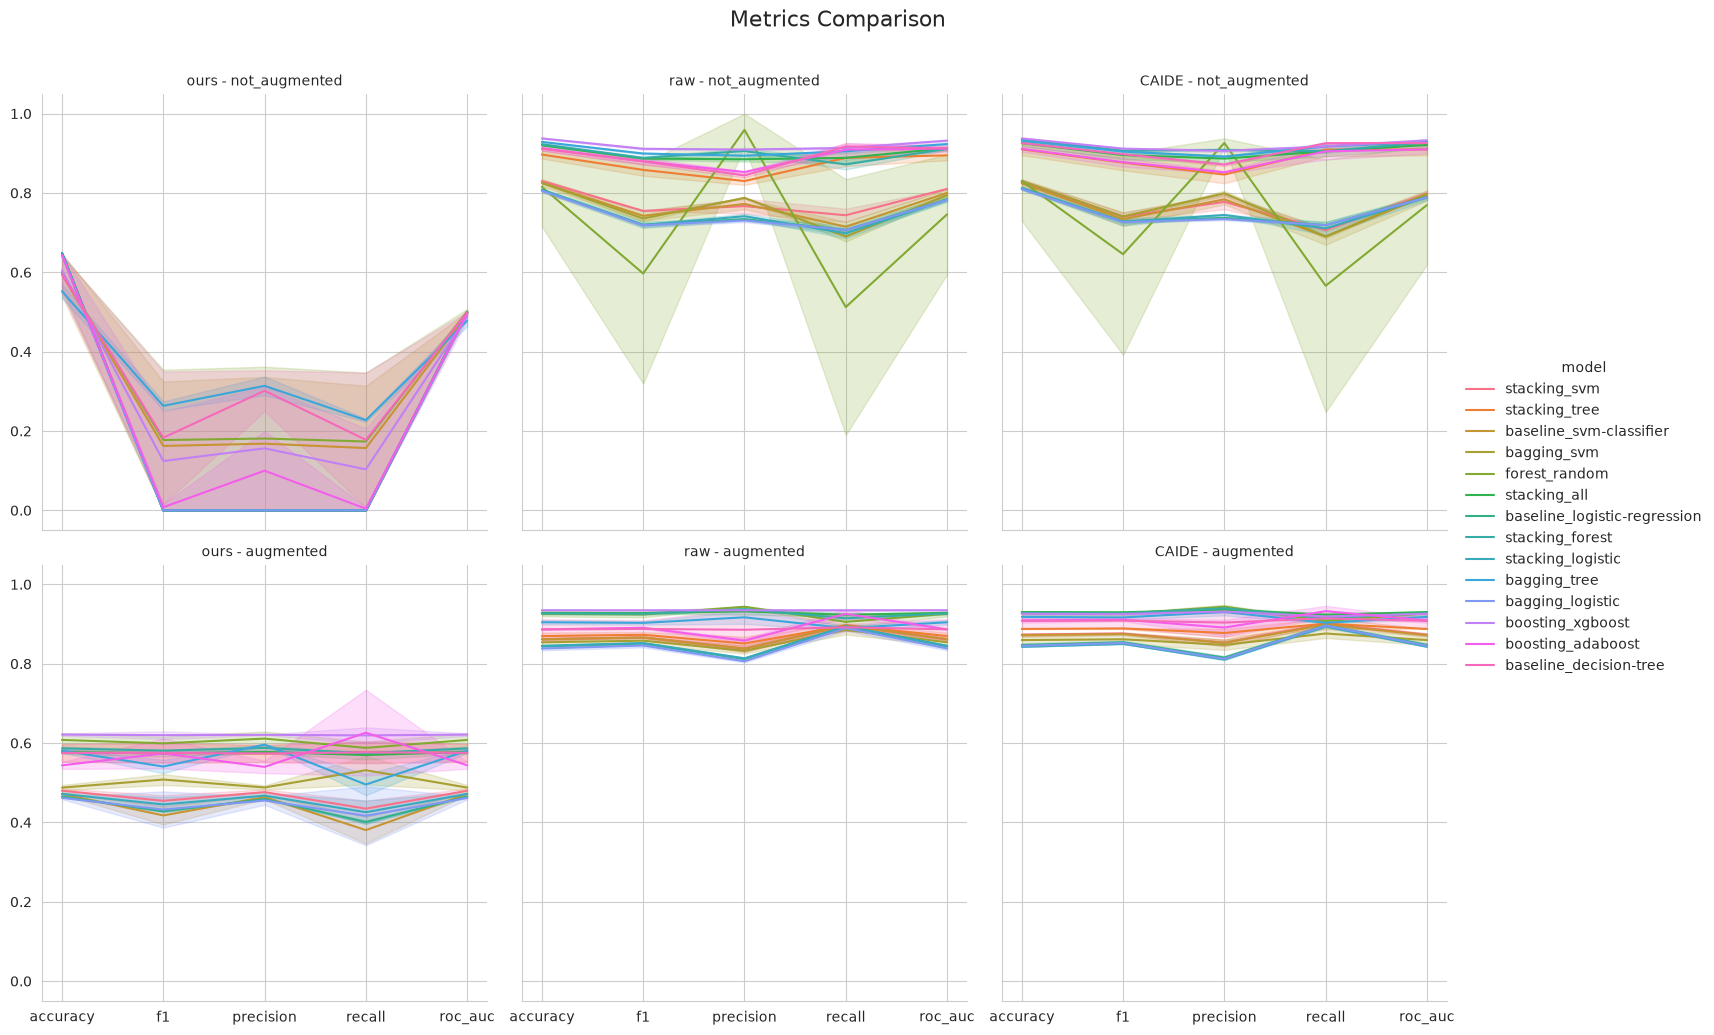

In [32]:
sns.set_style("whitegrid")
g = sns.relplot(
    kind='line',
    data=df_metrics_test,
    x='metric',
    y='value',
    hue='model',
    row='dataset_type',
    col='columns'
)
g.set_titles(template="{col_name} - {row_name}")
g.set_axis_labels("", "")
plt.suptitle('Metrics Comparison', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('comparison_metrics_per_model.png'), dpi=300, bbox_inches='tight')
plt.show()

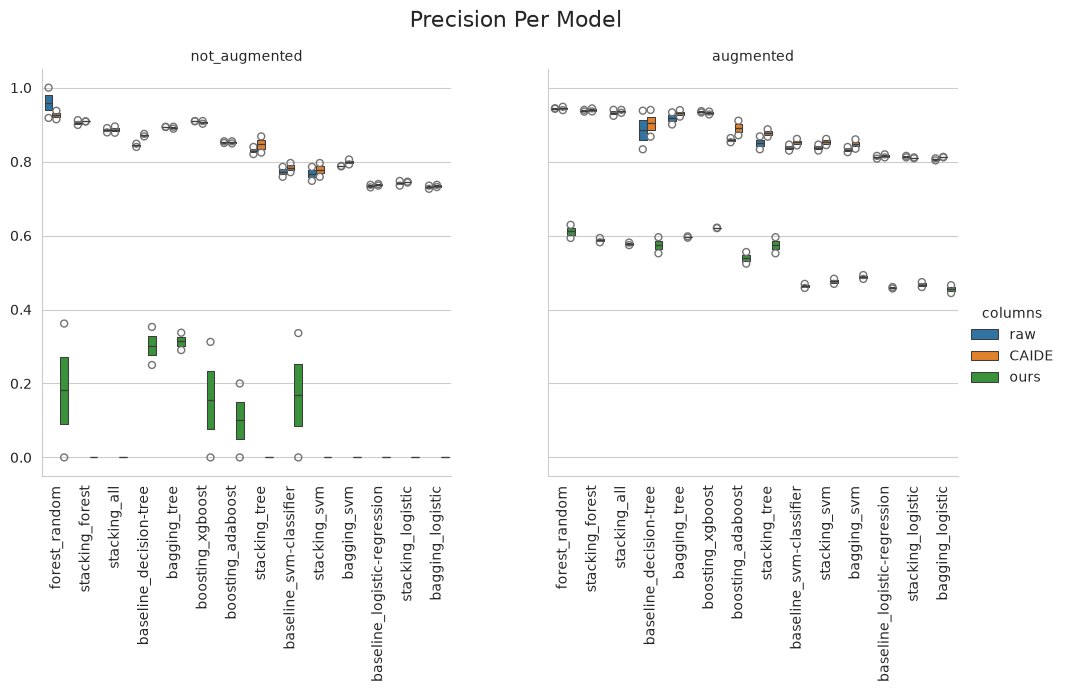

In [55]:
sns.set_style("whitegrid")
g = sns.catplot(
    kind="boxen", 
    data=df_metrics_test.loc[df_metrics_test['metric'] == 'precision'].sort_values(by='value', ascending=False), 
    x="model", 
    y='value',
    col='dataset_type',
    hue='columns')
g.set_xticklabels(rotation=90)
g.set_axis_labels('', '')
g.set_titles(template="{col_name}")
plt.suptitle('Precision Per Model', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('precision_per_model.png'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ROC AUC CURVE
# SHAP FOR RANDOM FOREST
# WHAT WAS THE BEST PARAM FOR RANDOM FOREST
# WHY THIS BEST PARAM
# EVAL THE TEST FROM KAGGLE
# SUBMIT
# MAKE STREAM LIT